# np.cnn demo

A small convolutional neural network library written from scratch with NumPy. Convolutions use `im2col`, so the heavy lifting is a single matrix product. This notebook explains `im2col`, shows that the old API still works, and trains CNNs on digits, MNIST and Fashion-MNIST.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt

from cnn import (Sequential, Conv2d, MaxPool2d, Flatten, Linear, ReLU, Dropout, Adam,
                 CNN, FCLayer, ConvLayer, set_seed)
from cnn.layers import _im2col
from cnn.reference import conv2d_forward_loops
from cnn.utils import load_digits, load_mnist, train_test_split
from cnn.viz import (plot_history, confusion_matrix, plot_confusion_matrix, plot_filters,
                     plot_feature_maps, plot_misclassified, plot_saliency, FilterRecorder,
                     animate_filters)

os.makedirs("assets", exist_ok=True)
os.makedirs("results", exist_ok=True)
set_seed(0)
summary = {}

## 1. How `im2col` works

Every k×k window of the input (with all its channels) becomes one row of a matrix `cols`. The convolution is then `cols @ W_flat.T + b`.

In [2]:
x = np.arange(16, dtype=np.float64).reshape(1, 1, 4, 4)
cols = _im2col(x, k=2, s=2, out_h=2, out_w=2)
print("input:\n", x[0, 0])
print("\ncols (one row per 2x2 window, stride 2):\n", cols)

conv = Conv2d(1, 3, 2, stride=2)
y = conv.forward(x)
ref = conv2d_forward_loops(x, conv.W, conv.b, stride=2)
print("\nmatches the loop version:", np.allclose(y, ref))

input:
 [[ 0.  1.  2.  3.]
 [ 4.  5.  6.  7.]
 [ 8.  9. 10. 11.]
 [12. 13. 14. 15.]]

cols (one row per 2x2 window, stride 2):
 [[ 0.  1.  4.  5.]
 [ 2.  3.  6.  7.]
 [ 8.  9. 12. 13.]
 [10. 11. 14. 15.]]

matches the loop version: True


In [3]:
xb = np.random.randn(32, 8, 14, 14).astype(np.float32)
c = Conv2d(8, 16, 3, padding=1)
def t(fn, reps=5):
    fn(); best = 1e9
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best * 1000
t_loops = t(lambda: conv2d_forward_loops(xb, c.W, c.b, 1, 1))
t_im2col = t(lambda: c.forward(xb))
print(f"forward, 32x8x14x14 -> 16 channels: loops {t_loops:.1f} ms, im2col {t_im2col:.1f} ms ({t_loops / t_im2col:.1f}x)")

forward, 32x8x14x14 -> 16 channels: loops 4.7 ms, im2col 1.8 ms (2.6x)


## 2. The old API still works

`CNN([ConvLayer(...), Flatten(), FCLayer(...)])` with images shaped `(N, 1, 8, 8)` and labels `(N, 10, 1)`. `ConvLayer` here is one 1-channel filter followed by ReLU, as in the original code. (That single-channel ReLU can start "dead" with an unlucky seed, so we fix a seed that trains.)

In [4]:
X, y = load_digits(normalize=False)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=0)
Xl, Xlt = Xtr.reshape(-1, 1, 8, 8), Xte.reshape(-1, 1, 8, 8)
Yl, Ylt = np.eye(10)[ytr].reshape(-1, 10, 1), np.eye(10)[yte].reshape(-1, 10, 1)

set_seed(1)
old = CNN(layers=[
    ConvLayer(k_dim=3, padding=1, stride=1),
    ConvLayer(k_dim=3, padding=1, stride=1),
    Flatten(),
    FCLayer(n_input=64, n_output=128, activation='relu'),
    FCLayer(n_input=128, n_output=64, activation='relu'),
    FCLayer(n_input=64, n_output=32, activation='relu'),
    FCLayer(n_input=32, n_output=10, activation='softmax'),
])
old.train(Xl, Yl, epochs=10, lr=0.001, verbose=False)
old.test(Xlt, Ylt)

Test accuracy:  95.543%


0.9554317548746518

## 3. Digits (8x8) with the new API

A `FilterRecorder` callback stores the first layer's filters after each epoch to make a GIF.

Test accuracy: 97.77%


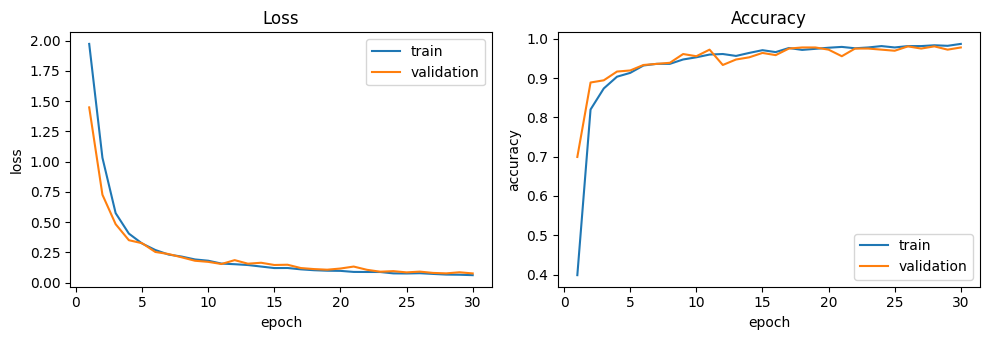

In [5]:
X, y = load_digits()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, seed=0)
Xtr, Xte = Xtr.reshape(-1, 1, 8, 8), Xte.reshape(-1, 1, 8, 8)

set_seed(0)
model = Sequential([Conv2d(1, 8, 3, padding=1), ReLU(), MaxPool2d(2), Flatten(), Linear(8 * 4 * 4, 10)])
rec = FilterRecorder(model.layers[0])
hist = model.fit(Xtr, ytr, epochs=30, batch_size=32, optimizer=Adam(lr=3e-3),
                 validation_data=(Xte, yte), callbacks=[rec], verbose=False)
_, acc = model.evaluate(Xte, yte)
summary["Digits 8x8"] = acc
print(f"Test accuracy: {acc * 100:.2f}%")
animate_filters(rec, "assets/digits_filters.gif", fps=4)
plot_history(hist, path="assets/digits_history.png")
plt.show()

## 4. MNIST (60k train / 10k test)

The first call downloads the dataset from OpenML and caches it in `~/.cache/npdl`.

In [6]:
def make_cnn():
    return Sequential([
        Conv2d(1, 8, 3, padding=1), ReLU(), MaxPool2d(2),
        Conv2d(8, 16, 3, padding=1), ReLU(), MaxPool2d(2),
        Flatten(), Linear(16 * 7 * 7, 128), ReLU(), Dropout(0.25), Linear(128, 10)])

(Xtr, ytr), (Xte, yte) = load_mnist(flatten=False)
set_seed(0)
model = make_cnn()
hist = model.fit(Xtr, ytr, epochs=5, batch_size=64, optimizer=Adam(lr=1e-3),
                 validation_data=(Xte, yte), verbose=True)
_, acc = model.evaluate(Xte, yte)
summary["MNIST"] = acc
print(f"\nMNIST test accuracy: {acc * 100:.2f}%")

Epoch 1/5 - loss: 0.2153 - accuracy: 93.312% - val_loss: 0.0774 - val_accuracy: 97.520%


Epoch 2/5 - loss: 0.0804 - accuracy: 97.483% - val_loss: 0.0453 - val_accuracy: 98.440%


Epoch 3/5 - loss: 0.0574 - accuracy: 98.210% - val_loss: 0.0410 - val_accuracy: 98.610%


Epoch 4/5 - loss: 0.0474 - accuracy: 98.523% - val_loss: 0.0461 - val_accuracy: 98.490%


Epoch 5/5 - loss: 0.0409 - accuracy: 98.733% - val_loss: 0.0368 - val_accuracy: 98.800%



MNIST test accuracy: 98.80%


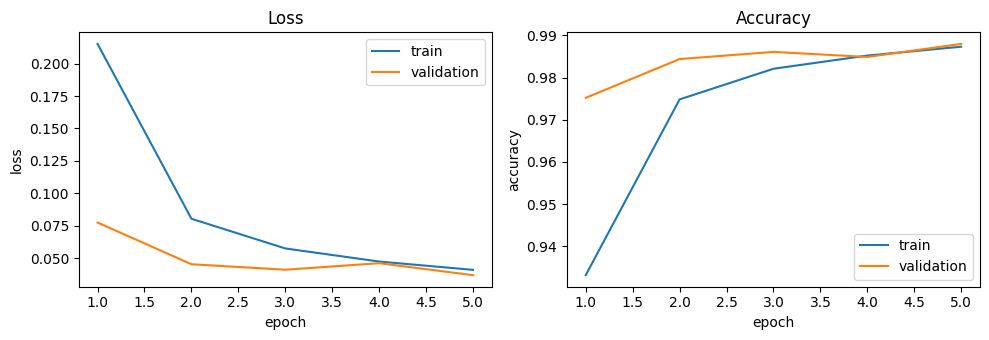

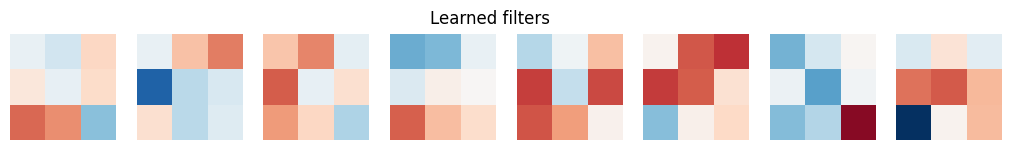

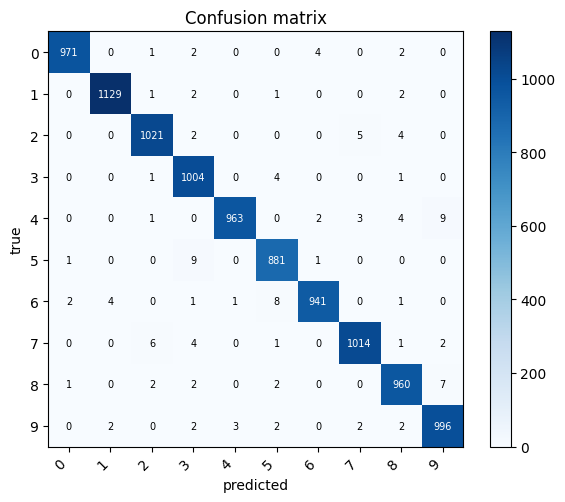

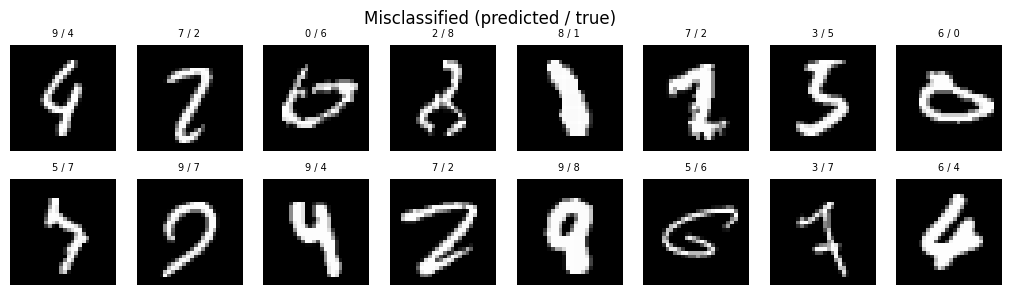

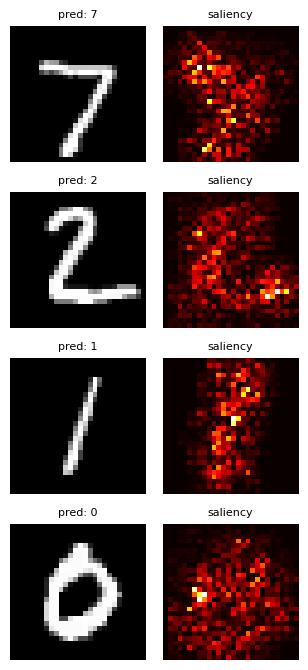

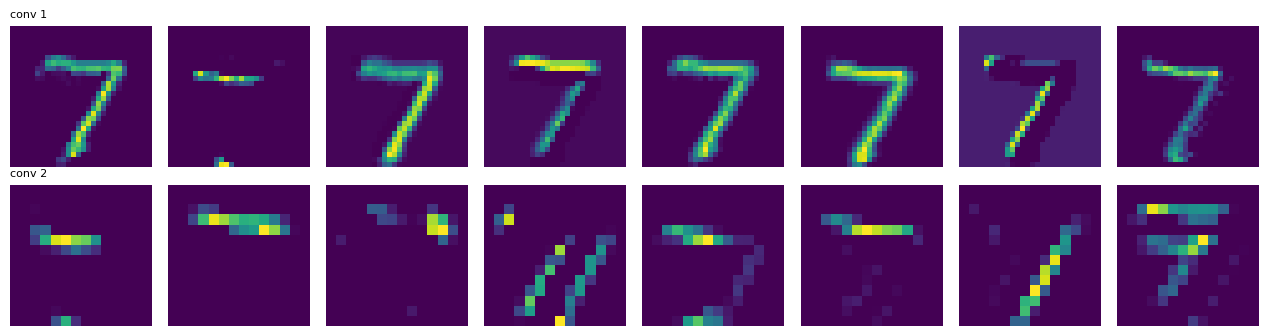

In [7]:
def report(prefix, model, Xte, yte, names=None):
    pred = model.predict(Xte)
    plot_confusion_matrix(confusion_matrix(yte, pred, 10), class_names=names, path=f"assets/{prefix}_confusion.png")
    plot_misclassified(Xte, yte, pred, class_names=names, n=16, path=f"assets/{prefix}_misclassified.png")
    plot_saliency(model, Xte, [0, 1, 2, 3], class_names=names, path=f"assets/{prefix}_saliency.png")
    plot_feature_maps(model, Xte[0], path=f"assets/{prefix}_feature_maps.png")

plot_history(hist, path="assets/mnist_history.png")
plot_filters(model.layers[0], path="assets/mnist_filters.png")
report("mnist", model, Xte, yte)
plt.show()

In [8]:
model.save("results/mnist_cnn.npz")
clone = make_cnn()
clone.load("results/mnist_cnn.npz")
_, acc2 = clone.evaluate(Xte, yte)
assert abs(acc - acc2) < 1e-9, "load() must reproduce the accuracy"
print(f"Reloaded model accuracy: {acc2 * 100:.2f}%")

Reloaded model accuracy: 98.80%


## 5. Fashion-MNIST

The same model, with class names.

Epoch 1/5 - loss: 0.4927 - accuracy: 82.102% - val_loss: 0.3739 - val_accuracy: 86.540%


Epoch 2/5 - loss: 0.3426 - accuracy: 87.522% - val_loss: 0.3256 - val_accuracy: 88.260%


Epoch 3/5 - loss: 0.3070 - accuracy: 88.825% - val_loss: 0.3081 - val_accuracy: 88.810%


Epoch 4/5 - loss: 0.2844 - accuracy: 89.597% - val_loss: 0.3119 - val_accuracy: 88.300%


Epoch 5/5 - loss: 0.2654 - accuracy: 90.255% - val_loss: 0.2870 - val_accuracy: 89.580%



Fashion-MNIST test accuracy: 89.58%


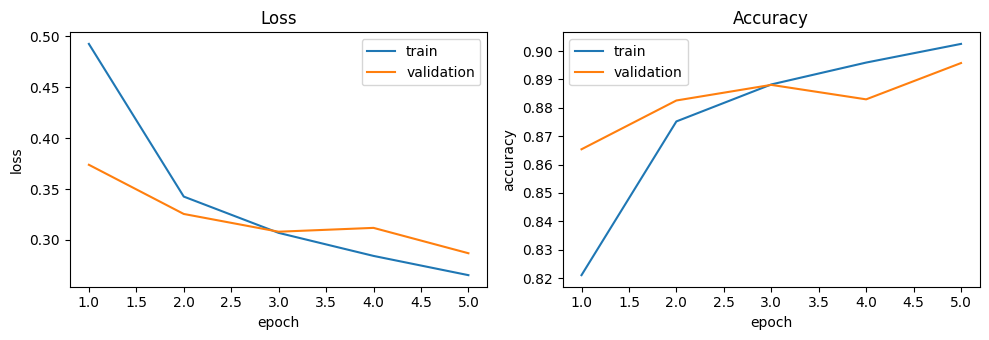

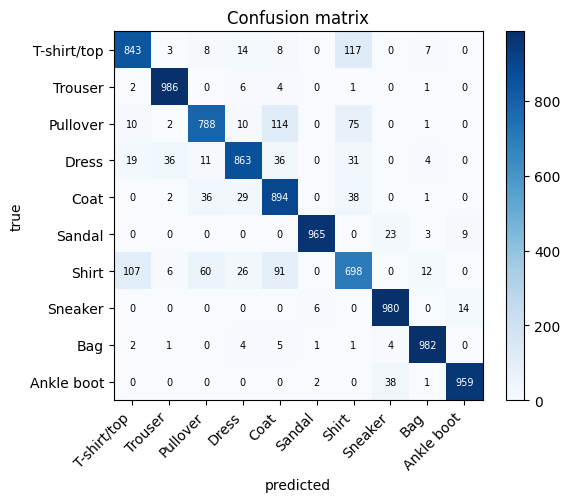

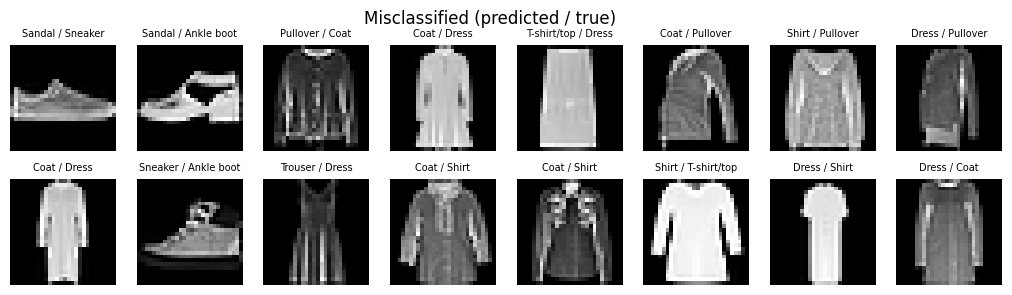

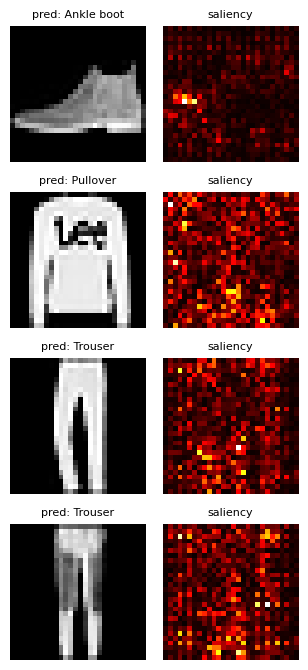

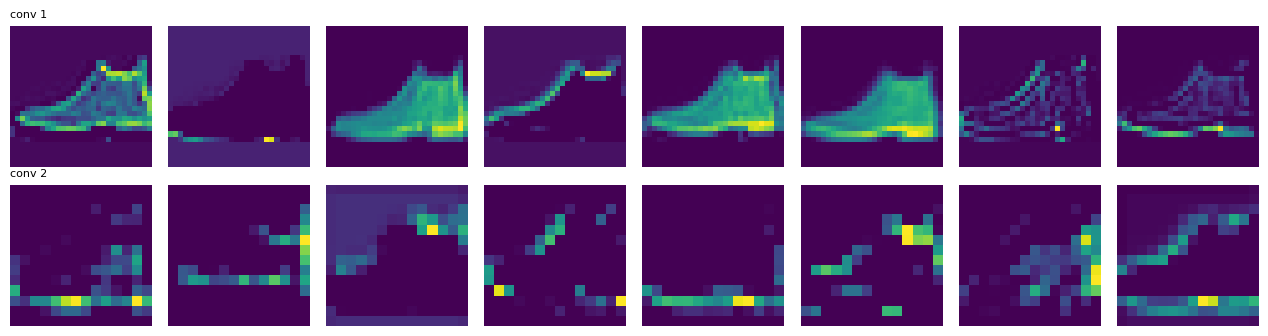

In [9]:
names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
(Xtr, ytr), (Xte, yte) = load_mnist("fashion", flatten=False)
set_seed(0)
model = make_cnn()
hist = model.fit(Xtr, ytr, epochs=5, batch_size=64, optimizer=Adam(lr=1e-3),
                 validation_data=(Xte, yte), verbose=True)
_, acc = model.evaluate(Xte, yte)
summary["Fashion-MNIST"] = acc
print(f"\nFashion-MNIST test accuracy: {acc * 100:.2f}%")
plot_history(hist, path="assets/fashion_history.png")
report("fashion", model, Xte, yte, names)
plt.show()

## 6. Summary

In [10]:
print("| Dataset | Test accuracy |\n|---|---|")
for k, v in summary.items():
    print(f"| {k} | {v * 100:.2f}% |")

| Dataset | Test accuracy |
|---|---|
| Digits 8x8 | 97.77% |
| MNIST | 98.80% |
| Fashion-MNIST | 89.58% |
